# Etapa 2 — Análise exploratória dos dados

Este notebook cria uma base horária para a Etapa 3 a partir das quatro fontes
coletadas. As previsões de onda e vento cobrem apenas sete dias; por isso, as
conclusões sobre elas descrevem a janela observada, não o clima de João Pessoa
ao longo do ano.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

## 1. Carregamento e diagnóstico

Há duas escalas temporais: `mares_2025.csv` descreve o ano de 2025, enquanto
ondas, vento e `mares_previsao.csv` descrevem a janela recente. A tábua anual
é usada para contextualizar as marés; a mensal é usada na junção final.

In [2]:
mares_ano = pd.read_csv(DIR_RAW / "mares_2025.csv")
mares_previsao = pd.read_csv(DIR_RAW / "mares_previsao.csv")
ondas = pd.read_csv(DIR_RAW / "ondas.csv")
vento = pd.read_csv(DIR_RAW / "vento.csv")

fontes = {
    "marés anuais": mares_ano,
    "marés da previsão": mares_previsao,
    "ondas": ondas,
    "vento": vento,
}

diagnostico = pd.DataFrame(
    {
        nome: {
            "linhas": len(tabela),
            "colunas": tabela.shape[1],
            "nulos": int(tabela.isna().sum().sum()),
            "duplicatas": int(tabela.duplicated().sum()),
        }
        for nome, tabela in fontes.items()
    }
).T
display(diagnostico)

assert (diagnostico[["nulos", "duplicatas"]] == 0).all().all(), (
    "A coleta contém nulos ou duplicatas; investigue antes de continuar."
)

,linhas,colunas,nulos,duplicatas
marés anuais,1410,6,0,0
marés da previsão,120,6,0,0
ondas,168,4,0,0
vento,168,4,0,0


As 1.410 observações anuais são coerentes com aproximadamente quatro extremos
de maré por dia. Já ondas e vento têm 168 horas cada: sete dias completos.

In [3]:
def preparar_mare(tabela: pd.DataFrame) -> pd.DataFrame:
    """Converte data/hora, padroniza categorias e valida eventos de maré."""
    resultado = tabela.copy()
    resultado["timestamp"] = pd.to_datetime(
        resultado["data"].astype(str) + " " + resultado["hora"].astype(str),
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )
    resultado["altura_m"] = pd.to_numeric(resultado["altura_m"], errors="raise")
    resultado["coeficiente"] = pd.to_numeric(resultado["coeficiente"], errors="raise")
    resultado["tipo"] = resultado["tipo"].str.strip().str.lower()
    resultado["classe_coeficiente"] = (
        resultado["classe_coeficiente"].str.strip().str.lower()
    )
    resultado = resultado.sort_values("timestamp").reset_index(drop=True)
    assert resultado["timestamp"].is_unique
    assert resultado["tipo"].isin(["alta", "baixa"]).all()
    return resultado


def preparar_previsao(tabela: pd.DataFrame, nome_valor: str) -> pd.DataFrame:
    """Converte uma previsão horária e torna explícita sua unidade."""
    resultado = tabela.copy()
    resultado["timestamp"] = pd.to_datetime(
        resultado["data"].astype(str) + " " + resultado["hora"].astype(str),
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )
    resultado = resultado.rename(columns={"valor": nome_valor, "direcao": f"direcao_{nome_valor}"})
    resultado[nome_valor] = pd.to_numeric(resultado[nome_valor], errors="raise")
    resultado[f"direcao_{nome_valor}"] = resultado[f"direcao_{nome_valor}"].str.strip().str.upper()
    resultado = resultado.sort_values("timestamp").reset_index(drop=True)
    assert resultado["timestamp"].is_unique
    assert resultado[nome_valor].ge(0).all()
    return resultado


mares_ano = preparar_mare(mares_ano)
mares_previsao = preparar_mare(mares_previsao)
ondas = preparar_previsao(ondas, "onda_m")
vento = preparar_previsao(vento, "vento_kmh")
fontes = {
    "marés anuais": mares_ano,
    "marés da previsão": mares_previsao,
    "ondas": ondas,
    "vento": vento,
}

display(
    pd.DataFrame(
        {
            nome: {
                "início": tabela["timestamp"].min(),
                "fim": tabela["timestamp"].max(),
                "tipos": ", ".join(map(str, tabela.dtypes.unique())),
            }
            for nome, tabela in fontes.items()
        }
    ).T
)

,início,fim,tipos
marés anuais,2025-01-01 05:50:00,2025-12-31 20:38:00,"str, float64, int64, datetime64[us]"
marés da previsão,2026-10-01 00:24:00,2026-10-31 20:58:00,"str, float64, int64, datetime64[us]"
ondas,2026-10-09 00:00:00,2026-10-15 23:00:00,"str, float64, datetime64[us]"
vento,2026-10-09 00:00:00,2026-10-15 23:00:00,"str, float64, datetime64[us]"


## 2. Marés: contexto anual

Os eventos de maré alta e baixa devem ocupar faixas distintas de altura. O
coeficiente é diário, portanto cada evento do mesmo dia repete seu valor.

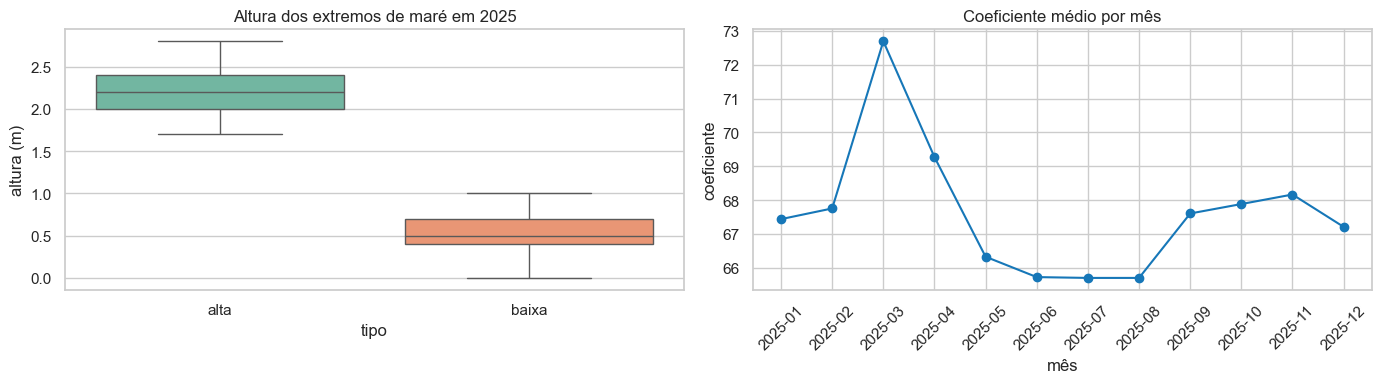

,count,min,median,max
tipo,,,,
alta,705,1.7,2.2,2.8
baixa,705,0.0,0.5,1.0


In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=mares_ano, x="tipo", y="altura_m", hue="tipo", legend=False, ax=eixos[0], palette="Set2")
eixos[0].set(title="Altura dos extremos de maré em 2025", xlabel="tipo", ylabel="altura (m)")

coef_mensal = (
    mares_ano.assign(mes=mares_ano["timestamp"].dt.to_period("M"))
    .groupby("mes", as_index=False)["coeficiente"].mean()
)
eixos[1].plot(coef_mensal["mes"].astype(str), coef_mensal["coeficiente"], marker="o", color="#1677b8")
eixos[1].tick_params(axis="x", rotation=45)
eixos[1].set(title="Coeficiente médio por mês", xlabel="mês", ylabel="coeficiente")
plt.tight_layout()
plt.show()

resumo_mares = mares_ano.groupby("tipo")["altura_m"].agg(["count", "min", "median", "max"]).round(2)
display(resumo_mares)

**Leitura:** as faixas de altura de marés altas e baixas ficam separadas,
como esperado para uma tábua de extremos. O coeficiente muda ao longo do ano;
ele entra no dataset porque resume a amplitude esperada da maré naquele dia.

## 3. Ondas e vento: janela de previsão

Antes da junção, verificamos o desenho intradiário e a distribuição das
direções. O número pequeno de dias exige cautela: padrões por hora podem ser
específicos desta semana.

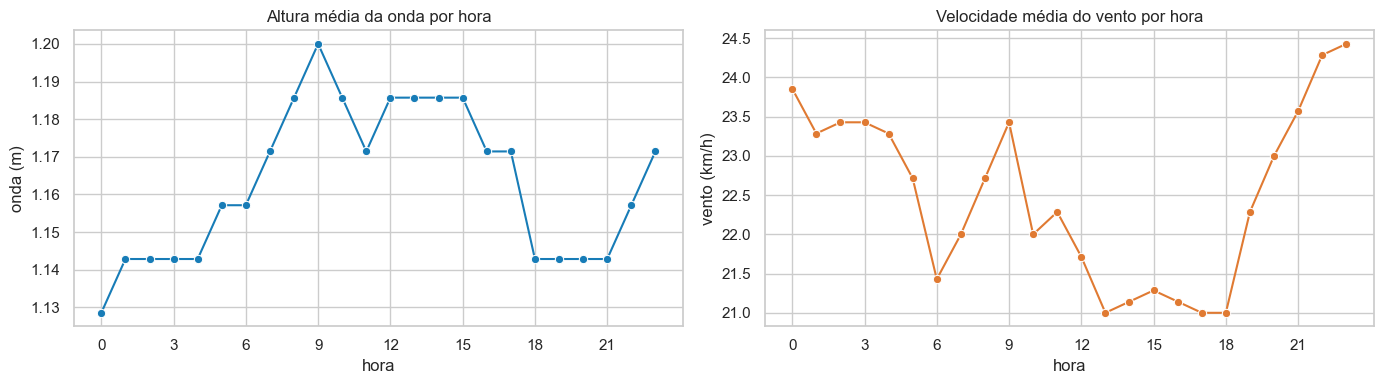

,ondas,vento
E,102,50
ESE,66,78
SE,0,38
ENE,0,2


In [5]:
previsao = ondas.merge(vento, on="timestamp", validate="one_to_one", suffixes=("_onda", "_vento"))
assert len(previsao) == len(ondas) == len(vento)

previsao["hora_dia"] = previsao["timestamp"].dt.hour
previsao["data"] = previsao["timestamp"].dt.date

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=previsao, x="hora_dia", y="onda_m", estimator="mean", errorbar=None, marker="o", ax=eixos[0], color="#177cb7")
eixos[0].set(title="Altura média da onda por hora", xlabel="hora", ylabel="onda (m)", xticks=range(0, 24, 3))

vento_por_hora = previsao.groupby("hora_dia", as_index=False)["vento_kmh"].mean()
sns.lineplot(data=vento_por_hora, x="hora_dia", y="vento_kmh", marker="o", ax=eixos[1], color="#e07a32")
eixos[1].set(title="Velocidade média do vento por hora", xlabel="hora", ylabel="vento (km/h)", xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

direcoes = pd.concat(
    [
        previsao["direcao_onda_m"].value_counts().rename("ondas"),
        previsao["direcao_vento_kmh"].value_counts().rename("vento"),
    ],
    axis=1,
).fillna(0).astype(int)
display(direcoes)

**Leitura:** ondas e vento variam ao longo da semana e do dia, enquanto as
direções predominantes podem ser comparadas diretamente no quadro acima. Não
inferimos causalidade entre eles: são previsões simultâneas, não medições
experimentais.

## 4. Junção horária e representação da maré

Uma maré é registrada apenas no extremo (alta ou baixa), mas ondas e vento
são horários. Para cada hora, buscamos o extremo anterior e o seguinte e
usamos uma transição de meia onda cossenoidal:

\(h(t)=h_0+(h_1-h_0)[1-\cos(\pi p)]/2\), em que \(p\) é a fração do
intervalo transcorrida. Ela preserva os valores observados e zera a inclinação
nos extremos, sendo mais coerente que uma reta. Ainda é uma aproximação: a
maré real sofre assimetrias locais e não foi medida hora a hora.

In [6]:
def interpolar_mare_coseno(grade_horaria: pd.DataFrame, eventos: pd.DataFrame) -> pd.DataFrame:
    """Projeta extremos de maré numa grade horária com interpolação cossenoidal."""
    alvos = grade_horaria[["timestamp"]].sort_values("timestamp").copy()
    extremos = eventos[["timestamp", "altura_m", "tipo"]].sort_values("timestamp").copy()

    anterior = pd.merge_asof(
        alvos,
        extremos.rename(
            columns={
                "timestamp": "timestamp_extremo_anterior",
                "altura_m": "altura_anterior",
                "tipo": "tipo_anterior",
            }
        ),
        left_on="timestamp",
        right_on="timestamp_extremo_anterior",
        direction="backward",
    )
    resultado = pd.merge_asof(
        anterior,
        extremos.rename(
            columns={
                "timestamp": "timestamp_extremo_posterior",
                "altura_m": "altura_posterior",
                "tipo": "tipo_posterior",
            }
        ),
        left_on="timestamp",
        right_on="timestamp_extremo_posterior",
        direction="forward",
    )

    if resultado[["altura_anterior", "altura_posterior"]].isna().any().any():
        raise ValueError("A grade contém horas fora da cobertura dos eventos de maré.")
    fracao = (
        (resultado["timestamp"] - resultado["timestamp_extremo_anterior"])
        / (resultado["timestamp_extremo_posterior"] - resultado["timestamp_extremo_anterior"])
    )
    resultado["mare_m"] = resultado["altura_anterior"] + (
        resultado["altura_posterior"] - resultado["altura_anterior"]
    ) * (1 - np.cos(np.pi * fracao)) / 2
    resultado["tendencia_mare"] = np.where(
        resultado["altura_posterior"] > resultado["altura_anterior"], "subindo", "descendo"
    )
    return resultado[["timestamp", "mare_m", "tendencia_mare"]]


mare_horaria = interpolar_mare_coseno(previsao, mares_previsao)
display(mare_horaria.head())

,timestamp,mare_m,tendencia_mare
0,2026-10-09 00:00:00,1.557382,subindo
1,2026-10-09 01:00:00,2.065947,subindo
2,2026-10-09 02:00:00,2.407154,subindo
3,2026-10-09 03:00:00,2.495257,descendo
4,2026-10-09 04:00:00,2.308114,descendo


In [7]:
coef_diario = (
    mares_previsao.assign(data=mares_previsao["timestamp"].dt.normalize())
    .groupby("data", as_index=False)
    .agg(coeficiente=("coeficiente", "first"), classe_coeficiente=("classe_coeficiente", "first"))
)
assert mares_previsao.assign(data=mares_previsao["timestamp"].dt.normalize()).groupby("data")["coeficiente"].nunique().le(1).all()

dataset = (
    previsao.drop(columns=["hora_dia", "data"])
    .merge(mare_horaria, on="timestamp", validate="one_to_one")
    .assign(data=lambda x: x["timestamp"].dt.normalize())
    .merge(coef_diario, on="data", how="left", validate="many_to_one")
    .drop(columns="data")
    .loc[:, [
        "timestamp", "onda_m", "direcao_onda_m", "vento_kmh", "direcao_vento_kmh",
        "mare_m", "tendencia_mare", "coeficiente", "classe_coeficiente",
    ]]
)

assert len(dataset) == 168
assert dataset.isna().sum().sum() == 0
assert dataset["timestamp"].is_monotonic_increasing
display(dataset.head(), dataset.describe(include="all"))

,timestamp,onda_m,direcao_onda_m,vento_kmh,direcao_vento_kmh,mare_m,tendencia_mare,coeficiente,classe_coeficiente
0,2026-10-09 00:00:00,1.0,ESE,23.0,SE,1.557382,subindo,95,muito alto
1,2026-10-09 01:00:00,1.0,ESE,22.0,SE,2.065947,subindo,95,muito alto
2,2026-10-09 02:00:00,1.0,ESE,23.0,SE,2.407154,subindo,95,muito alto
3,2026-10-09 03:00:00,1.0,ESE,24.0,SE,2.495257,descendo,95,muito alto
4,2026-10-09 04:00:00,1.0,ESE,24.0,ESE,2.308114,descendo,95,muito alto


,timestamp,onda_m,direcao_onda_m,vento_kmh,direcao_vento_kmh,mare_m,tendencia_mare,coeficiente,classe_coeficiente
count,168,168.000000,168,168.000000,168,168.000000,168,168.000000,168
unique,NaN,NaN,2,NaN,4,NaN,2,NaN,3
top,NaN,NaN,E,NaN,ESE,NaN,descendo,NaN,muito alto
freq,NaN,NaN,102,NaN,78,NaN,85,NaN,72
mean,2026-10-12 11:30:00,1.163095,NaN,22.488095,NaN,1.398322,NaN,80.285714,NaN
min,2026-10-09 00:00:00,0.900000,NaN,16.000000,NaN,0.204926,NaN,53.000000,NaN
25%,2026-10-10 17:45:00,1.000000,NaN,21.000000,NaN,0.735422,NaN,65.000000,NaN
50%,2026-10-12 11:30:00,1.200000,NaN,23.000000,NaN,1.410440,NaN,85.000000,NaN
75%,2026-10-14 05:15:00,1.300000,NaN,24.000000,NaN,2.066951,NaN,95.000000,NaN
max,2026-10-15 23:00:00,1.400000,NaN,28.000000,NaN,2.599958,NaN,96.000000,NaN


## 5. Condições coincidentes na janela

Os gráficos abaixo respondem à pergunta operacional: em que horas uma onda
maior coincide com vento mais fraco, e como a maré se posiciona nesses
momentos? A correlação é apenas descritiva e não deve ser interpretada como
efeito causal.

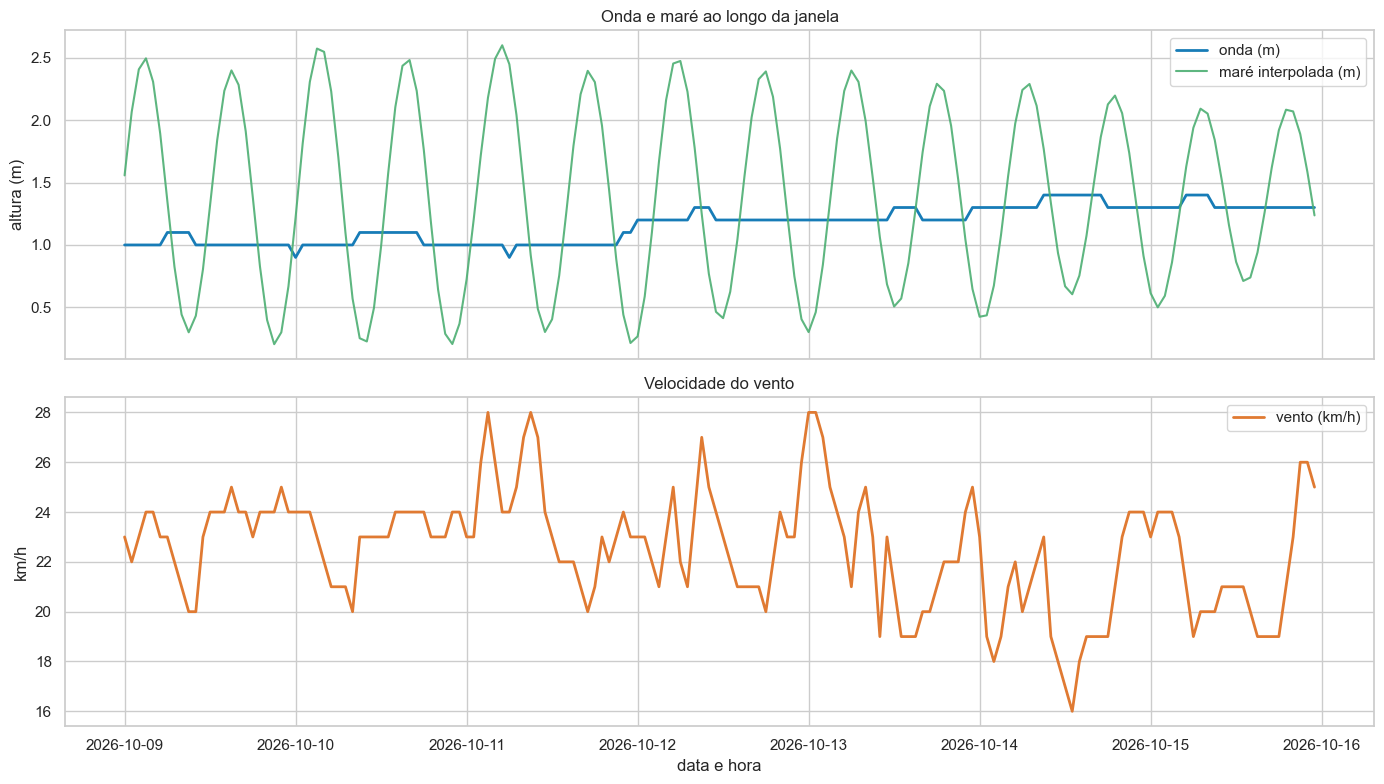

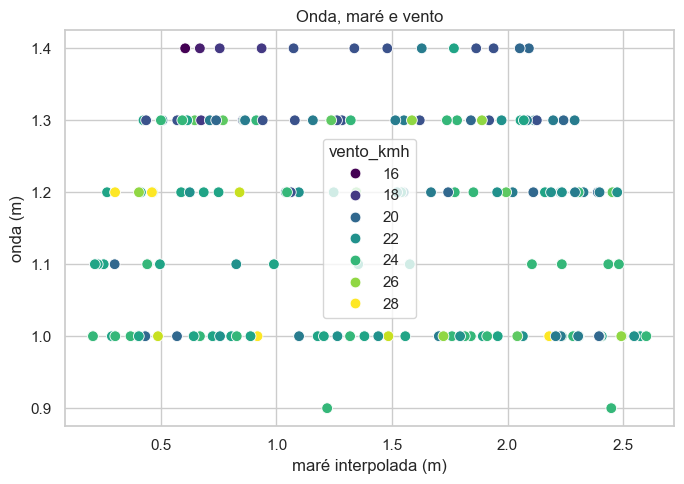

,onda_m,vento_kmh,mare_m,coeficiente
onda_m,1.00,-0.44,-0.06,-0.87
vento_kmh,-0.44,1.00,-0.02,0.37
mare_m,-0.06,-0.02,1.00,0.01
coeficiente,-0.87,0.37,0.01,1.00


In [8]:
fig, eixos = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
eixos[0].plot(dataset["timestamp"], dataset["onda_m"], label="onda (m)", color="#177cb7", linewidth=2)
eixos[0].plot(dataset["timestamp"], dataset["mare_m"], label="maré interpolada (m)", color="#4cae72", alpha=0.9)
eixos[0].set(title="Onda e maré ao longo da janela", ylabel="altura (m)")
eixos[0].legend()
eixos[1].plot(dataset["timestamp"], dataset["vento_kmh"], label="vento (km/h)", color="#e07a32", linewidth=2)
eixos[1].set(title="Velocidade do vento", xlabel="data e hora", ylabel="km/h")
eixos[1].legend()
plt.tight_layout()
plt.show()

fig, eixo = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=dataset, x="mare_m", y="onda_m", hue="vento_kmh", palette="viridis", s=60, ax=eixo)
eixo.set(title="Onda, maré e vento", xlabel="maré interpolada (m)", ylabel="onda (m)")
plt.tight_layout()
plt.show()

correlacoes = dataset[["onda_m", "vento_kmh", "mare_m", "coeficiente"]].corr().round(2)
display(correlacoes)

## 6. Exportação e conclusões

O arquivo final mantém o timestamp e unidades explícitas para reduzir
ambiguidades na etapa de modelagem. Direções e a tendência da maré são
categóricas; o notebook de ML deverá codificá-las a partir do conjunto de
treino, evitando vazamento de informação.

In [9]:
ARQUIVO_SAIDA = DIR_PROC / "dataset.csv"
dataset.to_csv(ARQUIVO_SAIDA, index=False)
print(f"Dataset salvo em {ARQUIVO_SAIDA.resolve()} com {len(dataset)} linhas e {dataset.shape[1]} colunas.")

melhor_onda_calma = dataset.sort_values(["onda_m", "vento_kmh"], ascending=[False, True]).iloc[0]
print(
    f"Na janela de {dataset['timestamp'].min():%d/%m/%Y} a {dataset['timestamp'].max():%d/%m/%Y}, "
    f"a onda variou de {dataset['onda_m'].min():.1f} a {dataset['onda_m'].max():.1f} m e o vento de "
    f"{dataset['vento_kmh'].min():.0f} a {dataset['vento_kmh'].max():.0f} km/h."
)
print(
    f"O maior compromisso observado entre onda alta e vento baixo ocorreu em "
    f"{melhor_onda_calma['timestamp']:%d/%m às %H:%M}: onda de {melhor_onda_calma['onda_m']:.1f} m, "
    f"vento de {melhor_onda_calma['vento_kmh']:.0f} km/h e maré estimada de "
    f"{melhor_onda_calma['mare_m']:.2f} m."
)
print(
    "Limitação principal: a maré horária é uma interpolação entre extremos e as "
    "previsões de onda/vento cobrem somente sete dias; os dados não permitem "
    "concluir padrões sazonais nem causalidade entre as variáveis."
)

Dataset salvo em C:\Users\Gustavo\Desktop\quando-voltar-jp\data\processed\dataset.csv com 168 linhas e 9 colunas.
Na janela de 09/10/2026 a 15/10/2026, a onda variou de 0.9 a 1.4 m e o vento de 16 a 28 km/h.
O maior compromisso observado entre onda alta e vento baixo ocorreu em 14/10 às 13:00: onda de 1.4 m, vento de 16 km/h e maré estimada de 0.61 m.
Limitação principal: a maré horária é uma interpolação entre extremos e as previsões de onda/vento cobrem somente sete dias; os dados não permitem concluir padrões sazonais nem causalidade entre as variáveis.
